# Section 4 — Regulatory Wind: กฎระเบียบเปลี่ยนเกม
**Business Question:** กฎใหม่กระทบใครหนักกว่ากัน และ Shopee ใช้เป็นโอกาสได้ไหม?

### ข้อมูลที่ใช้ (Verified Public Data)
1. **มาตรการจัดเก็บ VAT 7% สินค้านำเข้า < 1,500 บาท (กรมสรรพากร/กรมศุลกากร):** เก็บ VAT 7% ตั้งแต่บาทแรกของราคา CIF (เริ่ม 5 ก.ค. 2567)
2. **แนวปฏิบัติ กขค. (TCCT Guideline 6 ด้าน):** คุมความโปร่งใสค่าธรรมเนียม, ห้ามบังคับใช้ขนส่งรายเดียวอย่างไม่เป็นธรรม, และกำกับอัลกอริทึม (Self-preferencing / Visibility blocking)
3. **โครงการ "OTOP ไทยโตไกลกับ Shopee" (กรมการพัฒนาชุมชน x Shopee):** ลดค่า GP เหลือเริ่มต้น **4.00%** + ยกเว้นค่าธรรมเนียมโครงสร้างพื้นฐาน + โบนัสเครดิตโฆษณา 50–100%

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import chart_style

chart_style.setup_plot_style()
COLORS = chart_style.COLORS

heat_df = pd.read_csv("../data/processed/sec04_regulatory_heatmap.csv")
cost_df = pd.read_csv("../data/processed/sec04_cost_shift.csv")
display(heat_df)
display(cost_df)

,stakeholder,vat_import_1500,tcct_fee_cap,tcct_logistics,tcct_algorithm
0,ผู้ขาย Cross-border (จีน),5,2,3,3
1,Temu,5,3,4,4
2,TikTok Shop,3,4,3,5
3,Shopee,2,4,4,3
4,ผู้ขายในประเทศ (Local / OTOP),1,1,1,1


,seller_group,cost_before_pct,cost_after_pct,delta_pct,driver
0,ผู้ขาย Cross-border,18.5,25.5,7.0,"+7% VAT สินค้านำเข้า <1,500฿ และต้นทุนศุลกากร"
1,ผู้ขายในประเทศ (SME ปกติ),28.5,23.2,-5.3,มาตรการรัฐลดเพดาน GP (19.26% -> 13.91%)
2,ผู้ขาย OTOP (โครงการ Shopee),24.0,14.2,-9.8,เรตพิเศษ OTOP 4% + ยกเว้นค่าโครงสร้าง + เครดิต...


### กราฟ 4.1 — Regulatory Impact Heatmap
- **สื่ออะไร:** ผู้ขาย Cross-border จากจีนและ Temu ได้รับผลกระทบหนักที่สุด (ระดับ 5/5) จากกำแพงภาษี VAT นำเข้าและมาตรการคุมมาตรฐานสินค้า ขณะที่ผู้ขายในประเทศและโครงการ OTOP ของ Shopee ได้รับอานิสงส์เชิงโครงสร้าง

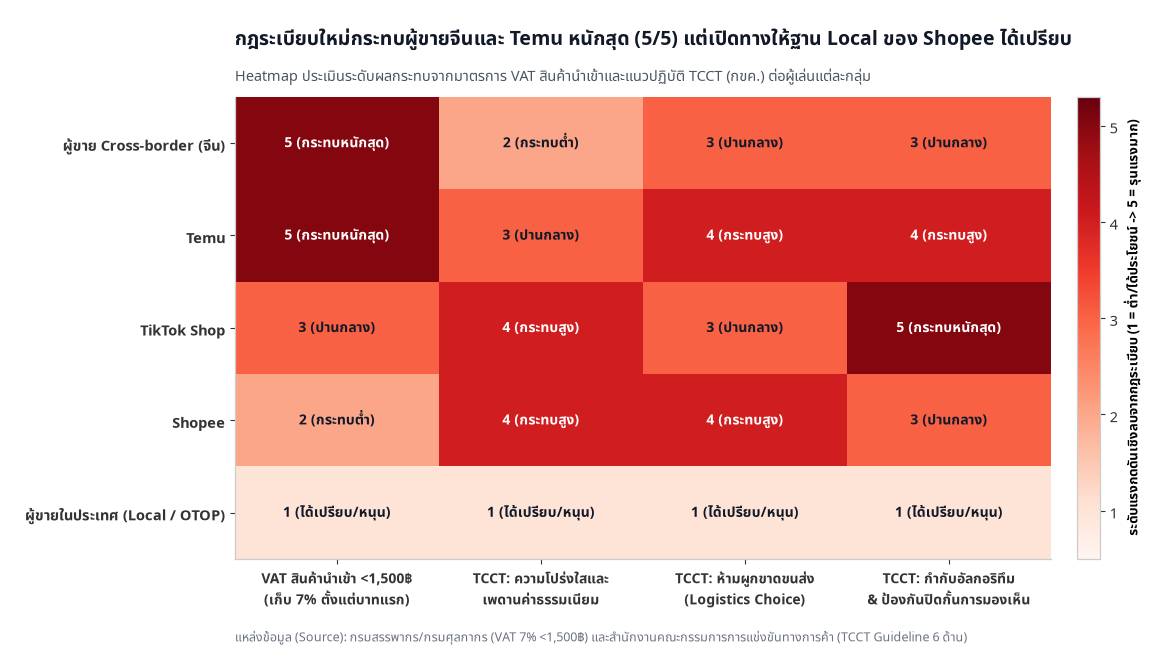

In [2]:
fig, ax = plt.subplots(figsize=(11.2, 6.0))

stakeholders = heat_df["stakeholder"].tolist()
measures = [
    "VAT สินค้านำเข้า <1,500฿\n(เก็บ 7% ตั้งแต่บาทแรก)",
    "TCCT: ความโปร่งใสและ\nเพดานค่าธรรมเนียม",
    "TCCT: ห้ามผูกขาดขนส่ง\n(Logistics Choice)",
    "TCCT: กำกับอัลกอริทึม\n& ป้องกันปิดกั้นการมองเห็น"
]
matrix = heat_df[["vat_import_1500", "tcct_fee_cap", "tcct_logistics", "tcct_algorithm"]].values

im = ax.imshow(matrix, cmap="Reds", vmin=0.5, vmax=5.3, aspect="auto")
ax.grid(False)

level_labels = {
    1: "1 (ได้เปรียบ/หนุน)",
    2: "2 (กระทบต่ำ)",
    3: "3 (ปานกลาง)",
    4: "4 (กระทบสูง)",
    5: "5 (กระทบหนักสุด)"
}

for i in range(len(stakeholders)):
    for j in range(len(measures)):
        val = matrix[i, j]
        txt_color = "#FFFFFF" if val >= 4 else "#111827"
        ax.text(j, i, level_labels[val], ha="center", va="center",
                fontsize=10, fontweight="bold", color=txt_color)

ax.set_xticks(np.arange(len(measures)))
ax.set_xticklabels(measures, fontsize=10, fontweight="bold")
ax.set_yticks(np.arange(len(stakeholders)))
ax.set_yticklabels(stakeholders, fontsize=10.5, fontweight="bold")

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.03)
cbar.set_label("ระดับแรงกดดันเชิงลบจากกฎระเบียบ (1 = ต่ำ/ได้ประโยชน์ -> 5 = รุนแรงมาก)", fontsize=9.5, fontweight="bold")

chart_style.add_title_and_source(
    ax,
    title="กฎระเบียบใหม่กระทบผู้ขายจีนและ Temu หนักสุด (5/5) แต่เปิดทางให้ฐาน Local ของ Shopee ได้เปรียบ",
    subtitle="Heatmap ประเมินระดับผลกระทบจากมาตรการ VAT สินค้านำเข้าและแนวปฏิบัติ TCCT (กขค.) ต่อผู้เล่นแต่ละกลุ่ม",
    source_text="กรมสรรพากร/กรมศุลกากร (VAT 7% <1,500฿) และสำนักงานคณะกรรมการการแข่งขันทางการค้า (TCCT Guideline 6 ด้าน)"
)

plt.savefig("../charts/04_1_regulatory_impact_heatmap.png")
plt.show()

### กราฟ 4.2 — Cost Shift Cross-border vs Local vs OTOP
- **สื่ออะไร:** ช่องว่างต้นทุนการขายระหว่างสินค้า Cross-border (พุ่งเป็น **25.5%**) กับสินค้า OTOP บน Shopee (ลดลงเหลือ **14.2%** ด้วยเรต GP 4%) ถ่างกว้างขึ้นถึง **11.3 percentage points** — กลายเป็นคูเมือง (Moat) ที่คู่แข่งจากจีนลอกเลียนแบบได้ยาก

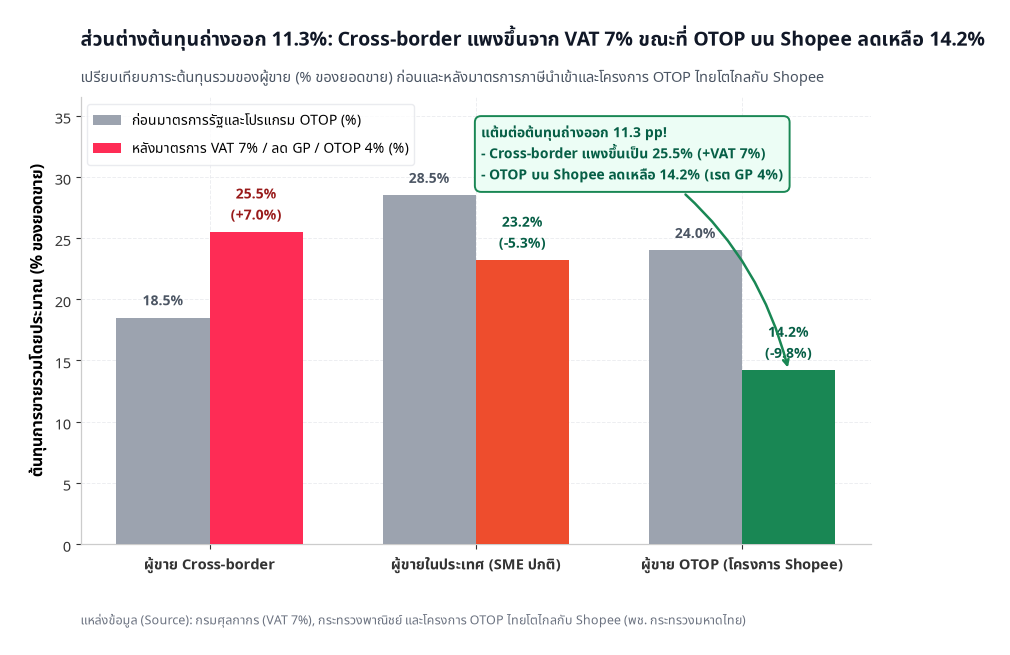

In [3]:
fig, ax = plt.subplots(figsize=(10.2, 5.8))

groups = cost_df["seller_group"].tolist()
x = np.arange(len(groups))
width = 0.35

before_vals = cost_df["cost_before_pct"].tolist()
after_vals = cost_df["cost_after_pct"].tolist()
deltas = cost_df["delta_pct"].tolist()

rects1 = ax.bar(x - width/2, before_vals, width, label="ก่อนมาตรการรัฐและโปรแกรม OTOP (%)", color="#9CA3AF", zorder=3)
after_colors = [COLORS["TikTok Red"], COLORS["Shopee"], COLORS["OTOP"]]
rects2 = ax.bar(x + width/2, after_vals, width, label="หลังมาตรการ VAT 7% / ลด GP / OTOP 4% (%)", color=after_colors, zorder=3)

for b in rects1:
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.5, f"{h:.1f}%",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color="#4B5563")

for i, b in enumerate(rects2):
    h = b.get_height()
    d = deltas[i]
    sign_color = "#991B1B" if d > 0 else "#065F46"
    ax.text(b.get_x() + b.get_width()/2, h + 0.5, f"{h:.1f}%\n({d:+.1f}%)",
            ha="center", va="bottom", fontsize=10, fontweight="bold", color=sign_color)

ax.annotate(
    "แต้มต่อต้นทุนถ่างออก 11.3 pp!\n- Cross-border แพงขึ้นเป็น 25.5% (+VAT 7%)\n- OTOP บน Shopee ลดเหลือ 14.2% (เรต GP 4%)",
    xy=(2 + width/2, 14.2), xytext=(1.02, 29.8),
    fontsize=10, fontweight="bold", color="#065F46",
    bbox=dict(boxstyle="round,pad=0.45", facecolor="#ECFDF5", edgecolor=COLORS["OTOP"], lw=1.4),
    arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=-0.2", color=COLORS["OTOP"], lw=1.8),
    zorder=5
)

ax.set_xticks(x)
ax.set_xticklabels(groups, fontsize=10.5, fontweight="bold")
ax.set_ylabel("ต้นทุนการขายรวมโดยประมาณ (% ของยอดขาย)", fontweight="bold")
ax.set_ylim(0, 36.5)
ax.legend(loc="upper left")

chart_style.add_title_and_source(
    ax,
    title="ส่วนต่างต้นทุนถ่างออก 11.3%: Cross-border แพงขึ้นจาก VAT 7% ขณะที่ OTOP บน Shopee ลดเหลือ 14.2%",
    subtitle="เปรียบเทียบภาระต้นทุนรวมของผู้ขาย (% ของยอดขาย) ก่อนและหลังมาตรการภาษีนำเข้าและโครงการ OTOP ไทยโตไกลกับ Shopee",
    source_text="กรมศุลกากร (VAT 7%), กระทรวงพาณิชย์ และโครงการ OTOP ไทยโตไกลกับ Shopee (พช. กระทรวงมหาดไทย)"
)

plt.savefig("../charts/04_2_cost_shift_comparison.png")
plt.show()

> **Insight ของ Section 4:** *"กฎระเบียบใหม่ไม่ใช่แค่ความเสี่ยงด้านค่าธรรมเนียม แต่เป็นลมหนุนสำคัญที่ทำให้ Moat ของ Shopee (ผู้ขายในประเทศ + OTOP เรต 4% + เครือข่าย SPX Express) มีความได้เปรียบเชิงต้นทุนเหนือสินค้านำเข้าชัดเจน"*